# Model Development and Training


In [409]:
#data handling
import pandas as pd
import numpy as np
#visualization
import matplotlib.pyplot as plt
import seaborn as sns
#machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
#baseline models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
#model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#file paths
from pathlib import Path
#reproducibility
import random

In [410]:
#define the dataset path
data_path = Path("../data/processed/energy_data_features.csv")

#load the dataset
df = pd.read_csv(data_path, parse_dates=["date"])

#display the first five rows
display(df.head())

#check dataset shape
print("Dataset shape :", df.shape)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,month,day_of_month,is_weekend,rolling_mean_1h,rolling_mean_3h,rolling_std_1h,lag_1,lag_3,lag_6,temp_humidity_interaction
0,2016-01-11 20:00:00,80,30,20.890000,51.193333,20.20,46.330000,20.200000,48.193333,18.963333,...,1,11,0,173.333333,135.000000,141.515606,70.0,100.0,430.0,1069.428733
1,2016-01-11 20:10:00,140,40,20.890000,49.800000,20.20,46.026667,20.166667,47.633333,19.033333,...,1,11,0,115.000000,136.111111,67.156534,80.0,90.0,250.0,1040.322000
2,2016-01-11 20:20:00,120,20,20.890000,48.433333,20.20,45.722500,20.166667,47.300000,19.175000,...,1,11,0,96.666667,140.555556,24.221203,140.0,70.0,100.0,1011.772333
3,2016-01-11 20:30:00,190,40,20.963333,47.633333,20.26,45.530000,20.200000,47.026667,19.260000,...,1,11,0,100.000000,144.444444,26.076810,120.0,80.0,100.0,998.553444
4,2016-01-11 20:40:00,110,40,21.033333,47.063333,20.29,45.223333,20.260000,46.826667,19.323333,...,1,11,0,115.000000,152.222222,45.055521,190.0,140.0,90.0,989.898778


Dataset shape : (19717, 40)


In [411]:
#display column names and data types
df.info()

#display statistical information
display(df.describe())

#check missing values
print("Total missing values :", df.isnull().sum().sum())

#check duplicate records
print("Duplicate rows :", df.duplicated().sum())

#check chronological order
print("Dates sorted :", df["date"].is_monotonic_increasing)

<class 'pandas.DataFrame'>
RangeIndex: 19717 entries, 0 to 19716
Data columns (total 40 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   date                       19717 non-null  datetime64[us]
 1   Appliances                 19717 non-null  int64         
 2   lights                     19717 non-null  int64         
 3   T1                         19717 non-null  float64       
 4   RH_1                       19717 non-null  float64       
 5   T2                         19717 non-null  float64       
 6   RH_2                       19717 non-null  float64       
 7   T3                         19717 non-null  float64       
 8   RH_3                       19717 non-null  float64       
 9   T4                         19717 non-null  float64       
 10  RH_4                       19717 non-null  float64       
 11  T5                         19717 non-null  float64       
 12  RH_5           

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,month,day_of_month,is_weekend,rolling_mean_1h,rolling_mean_3h,rolling_std_1h,lag_1,lag_3,lag_6,temp_humidity_interaction
count,19717,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,...,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000,19717.000000
mean,2016-03-20 07:00:00,97.660902,3.771365,21.688025,40.252312,20.342020,40.416201,22.269799,39.236639,20.857086,...,3.103565,16.062028,0.277527,97.628612,97.646588,37.205307,97.642643,97.617285,97.642643,874.053132
min,2016-01-11 20:00:00,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,...,1.000000,1.000000,0.000000,26.666667,33.333333,0.000000,10.000000,10.000000,10.000000,621.536667
25%,2016-02-15 01:30:00,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.533333,...,2.000000,9.000000,0.000000,50.000000,52.222222,7.527727,50.000000,50.000000,50.000000,787.727111
50%,2016-03-20 07:00:00,60.000000,0.000000,21.600000,39.633333,20.000000,40.500000,22.100000,38.530000,20.666667,...,3.000000,16.000000,0.000000,63.333333,69.444444,11.690452,60.000000,60.000000,60.000000,856.867556
75%,2016-04-23 12:30:00,100.000000,0.000000,22.600000,43.060000,21.500000,43.260000,23.290000,41.760000,22.100000,...,4.000000,23.000000,1.000000,110.000000,119.444444,27.868740,100.000000,100.000000,100.000000,936.301700
max,2016-05-27 18:00:00,1080.000000,50.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,...,5.000000,31.000000,1.000000,720.000000,465.000000,435.128334,1080.000000,1080.000000,1080.000000,1380.614400
std,NaN,102.472557,7.860370,1.606048,3.972151,2.193788,4.069172,2.005713,3.249997,2.042993,...,1.338305,8.453473,0.447790,81.379501,67.674509,57.076588,102.445407,102.412337,102.445407,119.133665


Total missing values : 0
Duplicate rows : 0
Dates sorted : True


In [412]:
#cyclical encoding so that 23:00 is close to 00:00 and Sunday is close to Monday
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["day_of_week_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["day_of_week_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

#remove date and target from input features
#rv1 is a random noise column, hour/day_of_week are replaced by the cyclical columns,
#month/day_of_month only take values in validation/test that never appear in training
X = df.drop(columns=[
    "date", "Appliances", "rv1",
    "hour", "day_of_week", "month", "day_of_month"
])

#select the target variable
y = df["Appliances"]

#display the results
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())


Input features shape: (19717, 37)
Target shape: (19717,)

Input features:
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'is_weekend', 'rolling_mean_1h', 'rolling_mean_3h', 'rolling_std_1h', 'lag_1', 'lag_3', 'lag_6', 'temp_humidity_interaction', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos']


### Chronological data splitting

In [413]:
#Split Dataset

#calculate split indexes
train_size = int(len(df) * 0.70) #for training
val_size = int(len(df) * 0.80) #for validation 70 + 10 = 80

#split input features
X_train = X.iloc[:train_size]
X_val = X.iloc[train_size:val_size]
X_test = X.iloc[val_size:]

#split target values
y_train = y.iloc[:train_size]
y_val = y.iloc[train_size:val_size]
y_test = y.iloc[val_size:]

#display dataset sizes
print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Testing data:", X_test.shape, y_test.shape)

Training data: (13801, 37) (13801,)
Validation data: (1972, 37) (1972,)
Testing data: (3944, 37) (3944,)


In [414]:
#Feature Scaling

#create a scaler for input features
X_scaler = StandardScaler() #scales the input features.

#create a scaler for the target variable
y_scaler = StandardScaler() #scales the appliance consumption target.

In [415]:
#Fit and transform the training data

#fit the input scaler using training data only
X_train_scaled = X_scaler.fit_transform(X_train)

#transform validation and testing data
X_val_scaled = X_scaler.transform(X_val)
X_test_scaled = X_scaler.transform(X_test)

#scale the target variable
y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)
y_val_scaled = y_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
)
y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Training features:", X_train_scaled.shape)
print("Validation features:", X_val_scaled.shape)
print("Testing features:", X_test_scaled.shape)

Training features: (13801, 37)
Validation features: (1972, 37)
Testing features: (3944, 37)


In [416]:
#Prepare baseline models (We Use Random Forest and Linear Regression)

#create Linear Regression model
lr_model = LinearRegression()

#create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100, #RF creates 100 decision trees
    random_state=42,
    n_jobs=-1 #it tells Python to use all available CPU cores
)

print("Baseline models created successfully")

Baseline models created successfully


In [417]:
#Train Random Forest

#using original training data
rf_model.fit(X_train, y_train)

print("Random Forest training completed")

Random Forest training completed


In [418]:
#Train Linear Regression

#using scaled training data
lr_model.fit(X_train_scaled, y_train_scaled.ravel())

print("Linear Regression training completed")

Linear Regression training completed


### Predict using Linear Regression

In [419]:
#predict using validation features
lr_predictions_scaled = lr_model.predict(X_val_scaled)

#convert predictions back to original Wh scale
lr_predictions = y_scaler.inverse_transform(
    lr_predictions_scaled.reshape(-1, 1)
).ravel()

print("Linear Regression predictions:")
print(lr_predictions[:10])

Linear Regression predictions:
[205.63599495 249.8727272  550.18947536 602.42878293 343.86343081
  97.44871958  90.2250793  101.38154612 286.15526022 294.86833553]


### Predict using Random Forest

In [420]:
#predict using original validation features
rf_predictions = rf_model.predict(X_val)

print("Random Forest predictions:")
print(rf_predictions[:10])

Random Forest predictions:
[282.3 227.7 392.4 400.5 297.5 171.8 189.6 182.5 256.6 256.6]


#### Evaluate both models

In [421]:
#calculate Linear Regression metrics
lr_mae = mean_absolute_error(y_val, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_val, lr_predictions))
lr_r2 = r2_score(y_val, lr_predictions)

#calculate Random Forest metrics
rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))
rf_r2 = r2_score(y_val, rf_predictions)

#create comparison table
baseline_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

display(baseline_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,27.3062,61.8888,0.5628
1,Random Forest,38.1862,72.9076,0.3933


In [422]:
#Prepare time series sequences


#number of time steps in each window (current row + 5 previous rows)
sequence_length = 6

#combine the scaled feature datasets in chronological order
X_all_scaled = np.concatenate([
    X_train_scaled,
    X_val_scaled,
    X_test_scaled
])

#combine the scaled target datasets
y_all_scaled = np.concatenate([
    y_train_scaled.ravel(),
    y_val_scaled.ravel(),
    y_test_scaled.ravel()
])

#function to create time series sequences
def create_sequences(X_data, y_data, start, end, sequence_length):

    X_sequences = []
    y_sequences = []

    for i in range(max(start, sequence_length - 1), end):

        #take the window ending at the current time step
        #(row i only holds past consumption through lag/rolling features, so it is safe to use)
        X_sequences.append(
            X_data[i - sequence_length + 1:i + 1]
        )

        #predict the target at the current time step
        y_sequences.append(y_data[i])

    return np.array(X_sequences), np.array(y_sequences)


#create training sequences
X_train_seq, y_train_seq = create_sequences(
    X_all_scaled, y_all_scaled,
    0, train_size, sequence_length
)

#create validation sequences
X_val_seq, y_val_seq = create_sequences(
    X_all_scaled, y_all_scaled,
    train_size, val_size, sequence_length
)

#create testing sequences
X_test_seq, y_test_seq = create_sequences(
    X_all_scaled, y_all_scaled,
    val_size, len(df), sequence_length
)

#display sequence shapes
print("Training sequences:", X_train_seq.shape)
print("Training targets:", y_train_seq.shape)

print("Validation sequences:", X_val_seq.shape)
print("Validation targets:", y_val_seq.shape)

print("Testing sequences:", X_test_seq.shape)
print("Testing targets:", y_test_seq.shape)


Training sequences: (13796, 6, 37)
Training targets: (13796,)
Validation sequences: (1972, 6, 37)
Validation targets: (1972,)
Testing sequences: (3944, 6, 37)
Testing targets: (3944,)


### Import PyTorch

In [423]:

#import PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

#import utilities for preparing and loading datasets
from torch.utils.data import TensorDataset, DataLoader

#check PyTorch version
print("PyTorch version:", torch.__version__)

#select available computing device
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Selected device:", device)

#fixed seed so that training results are reproducible
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()


PyTorch version: 2.15.0
Selected device: mps


### Convert NumPy arrays into PyTorch tensors

In [424]:

# Convert training data into PyTorch tensors
X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_seq, dtype=torch.float32)

# Convert validation data into PyTorch tensors
X_val_tensor = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_seq, dtype=torch.float32)

# Convert testing data into PyTorch tensors
X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_seq, dtype=torch.float32)

# Display tensor shapes
print("Training input:", X_train_tensor.shape)
print("Training target:", y_train_tensor.shape)

print("Validation input:", X_val_tensor.shape)
print("Validation target:", y_val_tensor.shape)

print("Testing input:", X_test_tensor.shape)
print("Testing target:", y_test_tensor.shape)


Training input: torch.Size([13796, 6, 37])
Training target: torch.Size([13796])
Validation input: torch.Size([1972, 6, 37])
Validation target: torch.Size([1972])
Testing input: torch.Size([3944, 6, 37])
Testing target: torch.Size([3944])


### Create DataLoaders

In [425]:

# Set batch size
batch_size = 64

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 216
Validation batches: 31
Testing batches: 62


#### Batch check

In [426]:

# Get one batch from the training DataLoader
sample_X, sample_y = next(iter(train_loader))

print("Batch input shape:", sample_X.shape)
print("Batch target shape:", sample_y.shape)


Batch input shape: torch.Size([64, 6, 37])
Batch target shape: torch.Size([64])


### Define the LSTM model

In [427]:



class LSTMModel(nn.Module):

    def __init__(self, input_size, hidden_size, dropout_rate):

        super(LSTMModel, self).__init__()

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        # Dropout layer
        self.dropout = nn.Dropout(dropout_rate)

        # Fully connected hidden layer
        self.fc1 = nn.Linear(hidden_size, 32)

        # ReLU activation
        self.relu = nn.ReLU()

        # Output layer
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):

        # Pass input through LSTM
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Select the final time step output
        last_output = lstm_output[:, -1, :]

        # Apply dropout
        output = self.dropout(last_output)

        # Fully connected layer
        output = self.fc1(output)

        # Apply ReLU
        output = self.relu(output)

        # Generate prediction
        output = self.fc2(output)

        return output.squeeze(-1)


#### Initialize the LSTM model

In [428]:

# Same starting weights on every run
set_seed()

# Define model parameters
input_size = X_train_seq.shape[2]
hidden_size = 64
dropout_rate = 0.2

# Create the LSTM model
lstm_model = LSTMModel(
    input_size=input_size,
    hidden_size=hidden_size,
    dropout_rate=dropout_rate
)

# Move model to selected device
lstm_model = lstm_model.to(device)

# Display model architecture
print(lstm_model)


LSTMModel(
  (lstm): LSTM(37, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


#### Define the loss function

In [429]:

# Huber loss: less dominated by the rare consumption spikes than MSE
criterion = nn.HuberLoss()

print("Loss function:", criterion)


Loss function: HuberLoss()


#### Define the optimizer

In [430]:

# Define Adam optimizer
optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Halve the learning rate when validation loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    factor=0.5,
    patience=3
)

print("Optimizer:", optimizer)


Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


#### Check the model parameters

In [431]:

total_parameters = sum(
    parameter.numel()
    for parameter in lstm_model.parameters()
)

print("Total trainable parameters:", total_parameters)


Total trainable parameters: 28481


### Configure training parameters

In [432]:

import copy

# Number of training iterations
num_epochs = 50

# Early stopping patience
patience = 7

# Store training and validation losses
train_losses = []
val_losses = []

# Track the best validation loss
best_val_loss = float("inf")

# Count epochs without improvement
epochs_without_improvement = 0

# Store best model weights
best_model_weights = None

print("Training configuration completed")


Training configuration completed


### Create the training loop (this is where the model learn)

In [433]:

for epoch in range(num_epochs):

    #Training phase

    lstm_model.train()

    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        # Move batch to selected device
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Generate predictions
        predictions = lstm_model(batch_X)

        # Calculate training loss
        loss = criterion(predictions, batch_y)

        # Calculate gradients
        loss.backward()

        # Clip gradients to keep LSTM/GRU training stable
        nn.utils.clip_grad_norm_(lstm_model.parameters(), max_norm=1.0)

        # Update model weights
        optimizer.step()

        running_train_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)


    #Validation phase

    lstm_model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            # Generate validation predictions
            predictions = lstm_model(batch_X)

            # Calculate validation loss
            loss = criterion(predictions, batch_y)

            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)


    # Adjust learning rate based on validation loss
    scheduler.step(epoch_val_loss)

    # Store losses
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)


    # Display progress
    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Training Loss: {epoch_train_loss:.4f} "
        f"Validation Loss: {epoch_val_loss:.4f}"
    )


    #Early stopping

    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss

        # Save the best model weights
        best_model_weights = copy.deepcopy(lstm_model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping triggered")
        break


# Restore the best model weights
lstm_model.load_state_dict(best_model_weights)

print("\nLSTM training completed!")
print("Best validation loss:", best_val_loss)


Epoch [1/50] Training Loss: 0.1786 Validation Loss: 0.1084
Epoch [2/50] Training Loss: 0.1341 Validation Loss: 0.1019
Epoch [3/50] Training Loss: 0.1297 Validation Loss: 0.0985
Epoch [4/50] Training Loss: 0.1272 Validation Loss: 0.0962
Epoch [5/50] Training Loss: 0.1250 Validation Loss: 0.0951
Epoch [6/50] Training Loss: 0.1234 Validation Loss: 0.0975
Epoch [7/50] Training Loss: 0.1220 Validation Loss: 0.0962
Epoch [8/50] Training Loss: 0.1200 Validation Loss: 0.0942
Epoch [9/50] Training Loss: 0.1189 Validation Loss: 0.0941
Epoch [10/50] Training Loss: 0.1159 Validation Loss: 0.0956
Epoch [11/50] Training Loss: 0.1155 Validation Loss: 0.0942
Epoch [12/50] Training Loss: 0.1145 Validation Loss: 0.0980
Epoch [13/50] Training Loss: 0.1113 Validation Loss: 0.0950
Epoch [14/50] Training Loss: 0.1097 Validation Loss: 0.0937
Epoch [15/50] Training Loss: 0.1076 Validation Loss: 0.0965
Epoch [16/50] Training Loss: 0.1068 Validation Loss: 0.0985
Epoch [17/50] Training Loss: 0.1052 Validation Lo

#### training and validation loss

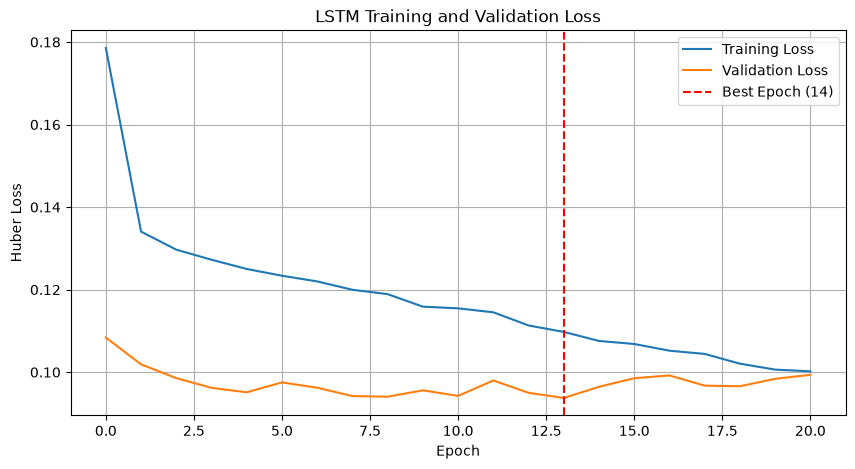

In [434]:

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

best_epoch = np.argmin(val_losses)

plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch + 1})"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.legend()
plt.grid(True)
plt.show()


#### Evaluate LSTM on validation data

In [435]:

# Set model to evaluation mode
lstm_model.eval()

# Store predictions
lstm_val_predictions = []

# Generate predictions
with torch.no_grad():

    for batch_X, batch_y in val_loader:

        batch_X = batch_X.to(device)

        predictions = lstm_model(batch_X)

        lstm_val_predictions.extend(
            predictions.cpu().numpy()
        )

# Convert predictions to original Wh scale
lstm_val_predictions = y_scaler.inverse_transform(
    np.array(lstm_val_predictions).reshape(-1, 1)
).ravel()

# Convert actual values to original Wh scale
lstm_val_actual = y_scaler.inverse_transform(
    y_val_seq.reshape(-1, 1)
).ravel()

# Calculate evaluation metrics
lstm_mae = mean_absolute_error(
    lstm_val_actual, lstm_val_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(lstm_val_actual, lstm_val_predictions)
)

lstm_r2 = r2_score(
    lstm_val_actual, lstm_val_predictions
)

print("LSTM Validation Results :")
print("MAE:", round(lstm_mae, 4))
print("RMSE:", round(lstm_rmse, 4))
print("R2 Score:", round(lstm_r2, 4))


LSTM Validation Results :
MAE: 23.7191
RMSE: 59.0042
R2 Score: 0.6026


### Define the GRU architecture

In [436]:

class GRUModel(nn.Module):

    def __init__(self, input_size, hidden_size, dropout_rate):

        super(GRUModel, self).__init__()

        # GRU layer
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        # Dropout layer
        self.dropout = nn.Dropout(dropout_rate)

        # Fully connected hidden layer
        self.fc1 = nn.Linear(hidden_size, 32)

        # ReLU activation
        self.relu = nn.ReLU()

        # Output layer
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):

        # Pass input through GRU
        gru_output, hidden_state = self.gru(x)

        # Select the final time step output
        last_output = gru_output[:, -1, :]

        # Apply dropout
        output = self.dropout(last_output)

        # Fully connected layer
        output = self.fc1(output)

        # Apply ReLU
        output = self.relu(output)

        # Generate prediction
        output = self.fc2(output)

        return output.squeeze(-1)


#### Initialize the GRU model

In [437]:

# Same starting weights on every run
set_seed()

# Define model parameters
input_size = X_train_seq.shape[2]
hidden_size = 64
dropout_rate = 0.2

# Create GRU model
gru_model = GRUModel(
    input_size=input_size,
    hidden_size=hidden_size,
    dropout_rate=dropout_rate
)

# Move model to selected device
gru_model = gru_model.to(device)

# Display architecture
print(gru_model)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in gru_model.parameters()
)

print("Total trainable parameters:", total_parameters)


GRUModel(
  (gru): GRU(37, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)
Total trainable parameters: 21889


### Configure GRU loss and optimizer

In [438]:

# Huber loss: less dominated by the rare consumption spikes than MSE
gru_criterion = nn.HuberLoss()

# Adam optimizer
gru_optimizer = optim.Adam(
    gru_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Halve the learning rate when validation loss stops improving
gru_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    gru_optimizer,
    factor=0.5,
    patience=3
)

print("GRU loss function:", gru_criterion)
print("GRU optimizer:", gru_optimizer)


GRU loss function: HuberLoss()
GRU optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


#### Configure GRU training

In [439]:

# Training configuration
num_epochs = 50
patience = 7

# Store GRU losses
gru_train_losses = []
gru_val_losses = []

# Track best validation loss
gru_best_val_loss = float("inf")

# Early stopping counter
gru_epochs_without_improvement = 0

# Store best model weights
gru_best_model_weights = None

print("GRU training configuration completed")


GRU training configuration completed


#### Train the GRU model

In [440]:

for epoch in range(num_epochs):

    #Training phase

    gru_model.train()

    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Clear previous gradients
        gru_optimizer.zero_grad()

        # Generate predictions
        predictions = gru_model(batch_X)

        # Calculate loss
        loss = gru_criterion(predictions, batch_y)

        # Backpropagation
        loss.backward()

        # Clip gradients to keep LSTM/GRU training stable
        nn.utils.clip_grad_norm_(gru_model.parameters(), max_norm=1.0)

        # Update model weights
        gru_optimizer.step()

        running_train_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)


    #validation phase

    gru_model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = gru_model(batch_X)

            loss = gru_criterion(predictions, batch_y)

            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)


    # Adjust learning rate based on validation loss
    gru_scheduler.step(epoch_val_loss)

    # Store losses
    gru_train_losses.append(epoch_train_loss)
    gru_val_losses.append(epoch_val_loss)


    # Display progress
    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Training Loss: {epoch_train_loss:.4f} "
        f"Validation Loss: {epoch_val_loss:.4f}"
    )


    #Early stopping

    if epoch_val_loss < gru_best_val_loss:

        gru_best_val_loss = epoch_val_loss

        gru_best_model_weights = copy.deepcopy(
            gru_model.state_dict()
        )

        gru_epochs_without_improvement = 0

    else:

        gru_epochs_without_improvement += 1

    if gru_epochs_without_improvement >= patience:

        print("GRU early stopping triggered")
        break


# Restore best weights
gru_model.load_state_dict(gru_best_model_weights)

print("\nGRU training completed")
print("Best validation loss:", gru_best_val_loss)


Epoch [1/50] Training Loss: 0.1710 Validation Loss: 0.1065
Epoch [2/50] Training Loss: 0.1346 Validation Loss: 0.0987
Epoch [3/50] Training Loss: 0.1312 Validation Loss: 0.1002
Epoch [4/50] Training Loss: 0.1280 Validation Loss: 0.1009
Epoch [5/50] Training Loss: 0.1265 Validation Loss: 0.0956
Epoch [6/50] Training Loss: 0.1255 Validation Loss: 0.0963
Epoch [7/50] Training Loss: 0.1252 Validation Loss: 0.0950
Epoch [8/50] Training Loss: 0.1235 Validation Loss: 0.0952
Epoch [9/50] Training Loss: 0.1224 Validation Loss: 0.0949
Epoch [10/50] Training Loss: 0.1204 Validation Loss: 0.0944
Epoch [11/50] Training Loss: 0.1205 Validation Loss: 0.0988
Epoch [12/50] Training Loss: 0.1189 Validation Loss: 0.0963
Epoch [13/50] Training Loss: 0.1190 Validation Loss: 0.0993
Epoch [14/50] Training Loss: 0.1172 Validation Loss: 0.0973
Epoch [15/50] Training Loss: 0.1153 Validation Loss: 0.0947
Epoch [16/50] Training Loss: 0.1144 Validation Loss: 0.0957
Epoch [17/50] Training Loss: 0.1137 Validation Lo

#### Plot GRU training progress

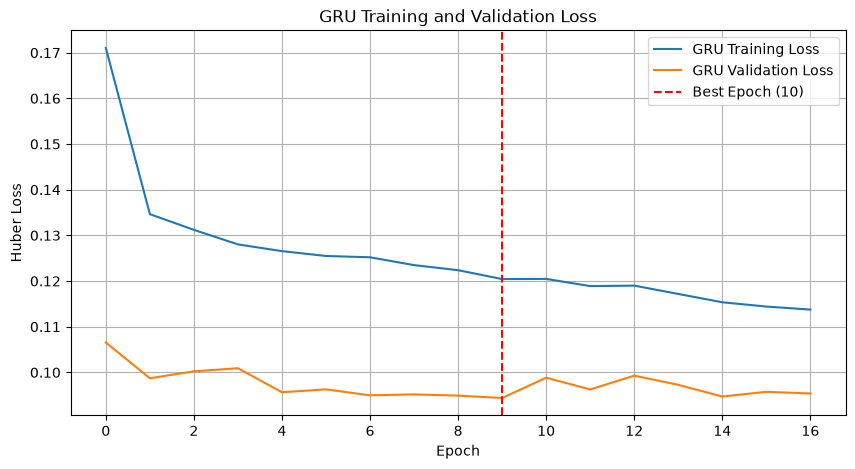

In [441]:

plt.figure(figsize=(10, 5))

plt.plot(gru_train_losses, label="GRU Training Loss")
plt.plot(gru_val_losses, label="GRU Validation Loss")

best_epoch = np.argmin(gru_val_losses)

plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch + 1})"
)

plt.title("GRU Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.legend()
plt.grid(True)
plt.show()


#### Evaluate GRU on validation data

In [442]:

gru_model.eval()

gru_val_predictions = []

with torch.no_grad():

    for batch_X, batch_y in val_loader:

        batch_X = batch_X.to(device)

        predictions = gru_model(batch_X)

        gru_val_predictions.extend(
            predictions.cpu().numpy()
        )

# Convert predictions to original Wh scale
gru_val_predictions = y_scaler.inverse_transform(
    np.array(gru_val_predictions).reshape(-1, 1)
).ravel()

# Convert actual values to original Wh scale
gru_val_actual = y_scaler.inverse_transform(
    y_val_seq.reshape(-1, 1)
).ravel()

# Calculate metrics
gru_mae = mean_absolute_error(
    gru_val_actual, gru_val_predictions
)

gru_rmse = np.sqrt(
    mean_squared_error(gru_val_actual, gru_val_predictions)
)

gru_r2 = r2_score(
    gru_val_actual, gru_val_predictions
)

print("GRU Validation Results :")
print("MAE:", round(gru_mae, 4))
print("RMSE:", round(gru_rmse, 4))
print("R2 Score:", round(gru_r2, 4))


GRU Validation Results :
MAE: 23.8904
RMSE: 59.4637
R2 Score: 0.5964


### CNN-LSTM

#### Define CNN-LSTM architecture


In [443]:

class CNNLSTMModel(nn.Module):

    def __init__(self, input_size, hidden_size, dropout_rate):

        super(CNNLSTMModel, self).__init__()

        # CNN layer
        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=64,
            kernel_size=2
        )

        # ReLU activation
        self.relu = nn.ReLU()

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=hidden_size,
            batch_first=True
        )

        # Dropout
        self.dropout = nn.Dropout(dropout_rate)

        # Dense layer
        self.fc1 = nn.Linear(hidden_size, 32)

        # Output layer
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):

        # Change input shape for CNN
        x = x.transpose(1, 2)

        # Extract local patterns using CNN
        x = self.conv1(x)

        # Apply ReLU
        x = self.relu(x)

        # Change shape back for LSTM
        x = x.transpose(1, 2)

        # Pass CNN output into LSTM
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Get final time step
        output = lstm_output[:, -1, :]

        # Apply dropout
        output = self.dropout(output)

        # Dense layer
        output = self.fc1(output)

        # ReLU activation
        output = self.relu(output)

        # Prediction
        output = self.fc2(output)

        return output.squeeze(-1)


### Initialize CNN-LSTM

In [444]:

# Same starting weights on every run
set_seed()

# Define model parameters
input_size = X_train_seq.shape[2]
hidden_size = 64
dropout_rate = 0.2

# Create CNN-LSTM model
cnn_lstm_model = CNNLSTMModel(
    input_size=input_size,
    hidden_size=hidden_size,
    dropout_rate=dropout_rate
)

# Move model to selected device
cnn_lstm_model = cnn_lstm_model.to(device)

# Display architecture
print(cnn_lstm_model)

# Count trainable parameters
cnn_lstm_parameters = sum(
    parameter.numel()
    for parameter in cnn_lstm_model.parameters()
    if parameter.requires_grad
)

print("Total trainable parameters:", cnn_lstm_parameters)


CNNLSTMModel(
  (conv1): Conv1d(37, 64, kernel_size=(2,), stride=(1,))
  (relu): ReLU()
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)
Total trainable parameters: 40193


#### Configure loss function

In [445]:

#  less dominated by the rare consumption spikes than MSE
cnn_lstm_criterion = nn.HuberLoss()

print("CNN-LSTM loss function:", cnn_lstm_criterion)


CNN-LSTM loss function: HuberLoss()


#### Configure Adam optimizer

In [446]:

# Define Adam optimizer
cnn_lstm_optimizer = optim.Adam(
    cnn_lstm_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Halve the learning rate when validation loss stops improving
cnn_lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    cnn_lstm_optimizer,
    factor=0.5,
    patience=3
)

print("CNN-LSTM optimizer:", cnn_lstm_optimizer)


CNN-LSTM optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


#### Configure training

In [447]:

# Training configuration
num_epochs = 50
patience = 7

# Store training and validation losses
cnn_lstm_train_losses = []
cnn_lstm_val_losses = []

# Track best validation loss
cnn_lstm_best_val_loss = float("inf")

# Early stopping counter
cnn_lstm_epochs_without_improvement = 0

# Store best model weights
cnn_lstm_best_model_weights = None

print("CNN-LSTM training configuration completed")


CNN-LSTM training configuration completed


#### CNN-LSTM training loop

In [448]:

for epoch in range(num_epochs):

    #training phase

    cnn_lstm_model.train()

    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Clear previous gradients
        cnn_lstm_optimizer.zero_grad()

        # Generate predictions
        predictions = cnn_lstm_model(batch_X)

        # Calculate training loss
        loss = cnn_lstm_criterion(predictions, batch_y)

        # Backpropagation
        loss.backward()

        # Clip gradients to keep LSTM/GRU training stable
        nn.utils.clip_grad_norm_(cnn_lstm_model.parameters(), max_norm=1.0)

        # Update model weights
        cnn_lstm_optimizer.step()

        running_train_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = (
        running_train_loss / len(train_loader.dataset)
    )


    #validation phase

    cnn_lstm_model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = cnn_lstm_model(batch_X)

            loss = cnn_lstm_criterion(predictions, batch_y)

            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = (
        running_val_loss / len(val_loader.dataset)
    )


    # Adjust learning rate based on validation loss
    cnn_lstm_scheduler.step(epoch_val_loss)

    # Store losses
    cnn_lstm_train_losses.append(epoch_train_loss)
    cnn_lstm_val_losses.append(epoch_val_loss)


    # Display progress
    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Training Loss: {epoch_train_loss:.4f} "
        f"Validation Loss: {epoch_val_loss:.4f}"
    )


    #early stopping

    if epoch_val_loss < cnn_lstm_best_val_loss:

        cnn_lstm_best_val_loss = epoch_val_loss

        cnn_lstm_best_model_weights = copy.deepcopy(
            cnn_lstm_model.state_dict()
        )

        cnn_lstm_epochs_without_improvement = 0

    else:

        cnn_lstm_epochs_without_improvement += 1

    if cnn_lstm_epochs_without_improvement >= patience:

        print("CNN-LSTM early stopping triggered")
        break


# Restore the best model weights
cnn_lstm_model.load_state_dict(
    cnn_lstm_best_model_weights
)

print("\nCNN-LSTM training completed")
print("Best validation loss:", cnn_lstm_best_val_loss)


Epoch [1/50] Training Loss: 0.1798 Validation Loss: 0.1032
Epoch [2/50] Training Loss: 0.1317 Validation Loss: 0.0999
Epoch [3/50] Training Loss: 0.1269 Validation Loss: 0.0951
Epoch [4/50] Training Loss: 0.1225 Validation Loss: 0.0939
Epoch [5/50] Training Loss: 0.1212 Validation Loss: 0.0936
Epoch [6/50] Training Loss: 0.1182 Validation Loss: 0.0950
Epoch [7/50] Training Loss: 0.1174 Validation Loss: 0.0923
Epoch [8/50] Training Loss: 0.1130 Validation Loss: 0.0965
Epoch [9/50] Training Loss: 0.1127 Validation Loss: 0.0940
Epoch [10/50] Training Loss: 0.1108 Validation Loss: 0.0938
Epoch [11/50] Training Loss: 0.1096 Validation Loss: 0.0972
Epoch [12/50] Training Loss: 0.1053 Validation Loss: 0.0952
Epoch [13/50] Training Loss: 0.1028 Validation Loss: 0.0976
Epoch [14/50] Training Loss: 0.1017 Validation Loss: 0.0978
CNN-LSTM early stopping triggered

CNN-LSTM training completed
Best validation loss: 0.09229166642526584


#### Plot training and validation loss

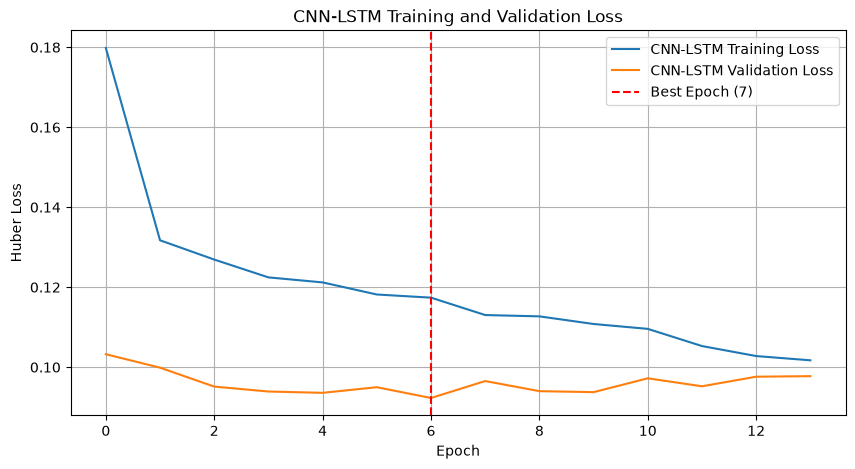

In [449]:

plt.figure(figsize=(10, 5))

plt.plot(
    cnn_lstm_train_losses,
    label="CNN-LSTM Training Loss"
)

plt.plot(
    cnn_lstm_val_losses,
    label="CNN-LSTM Validation Loss"
)

best_epoch = np.argmin(cnn_lstm_val_losses)

plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch + 1})"
)

plt.title("CNN-LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.legend()
plt.grid(True)
plt.show()


#### Evaluate CNN-LSTM on validation data

In [450]:

cnn_lstm_model.eval()

cnn_lstm_val_predictions = []

with torch.no_grad():

    for batch_X, batch_y in val_loader:

        batch_X = batch_X.to(device)

        predictions = cnn_lstm_model(batch_X)

        cnn_lstm_val_predictions.extend(
            predictions.cpu().numpy()
        )

# Convert predictions to original Wh scale
cnn_lstm_val_predictions = y_scaler.inverse_transform(
    np.array(cnn_lstm_val_predictions).reshape(-1, 1)
).ravel()

# Convert actual values to original Wh scale
cnn_lstm_val_actual = y_scaler.inverse_transform(
    y_val_seq.reshape(-1, 1)
).ravel()

# Calculate evaluation metrics
cnn_lstm_mae = mean_absolute_error(
    cnn_lstm_val_actual,
    cnn_lstm_val_predictions
)

cnn_lstm_rmse = np.sqrt(
    mean_squared_error(
        cnn_lstm_val_actual,
        cnn_lstm_val_predictions
    )
)

cnn_lstm_r2 = r2_score(
    cnn_lstm_val_actual,
    cnn_lstm_val_predictions
)

print("CNN-LSTM Validation Results :")
print("MAE:", round(cnn_lstm_mae, 4))
print("RMSE:", round(cnn_lstm_rmse, 4))
print("R2 Score:", round(cnn_lstm_r2, 4))


CNN-LSTM Validation Results :
MAE: 24.0308
RMSE: 58.6928
R2 Score: 0.6068


### comparison table

In [451]:

# Create model comparison DataFrame
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "LSTM",
        "GRU",
        "CNN-LSTM"
    ],
    "MAE": [
        lr_mae,
        rf_mae,
        lstm_mae,
        gru_mae,
        cnn_lstm_mae
    ],
    "RMSE": [
        lr_rmse,
        rf_rmse,
        lstm_rmse,
        gru_rmse,
        cnn_lstm_rmse
    ],
    "R2 Score": [
        lr_r2,
        rf_r2,
        lstm_r2,
        gru_r2,
        cnn_lstm_r2
    ]
})

display(model_comparison.round(4))


,Model,MAE,RMSE,R2 Score
0,Linear Regression,27.3062,61.8888,0.5628
1,Random Forest,38.1862,72.9076,0.3933
2,LSTM,23.7191,59.0042,0.6026
3,GRU,23.8904,59.4637,0.5964
4,CNN-LSTM,24.0308,58.6928,0.6068


#### Visualize model performance

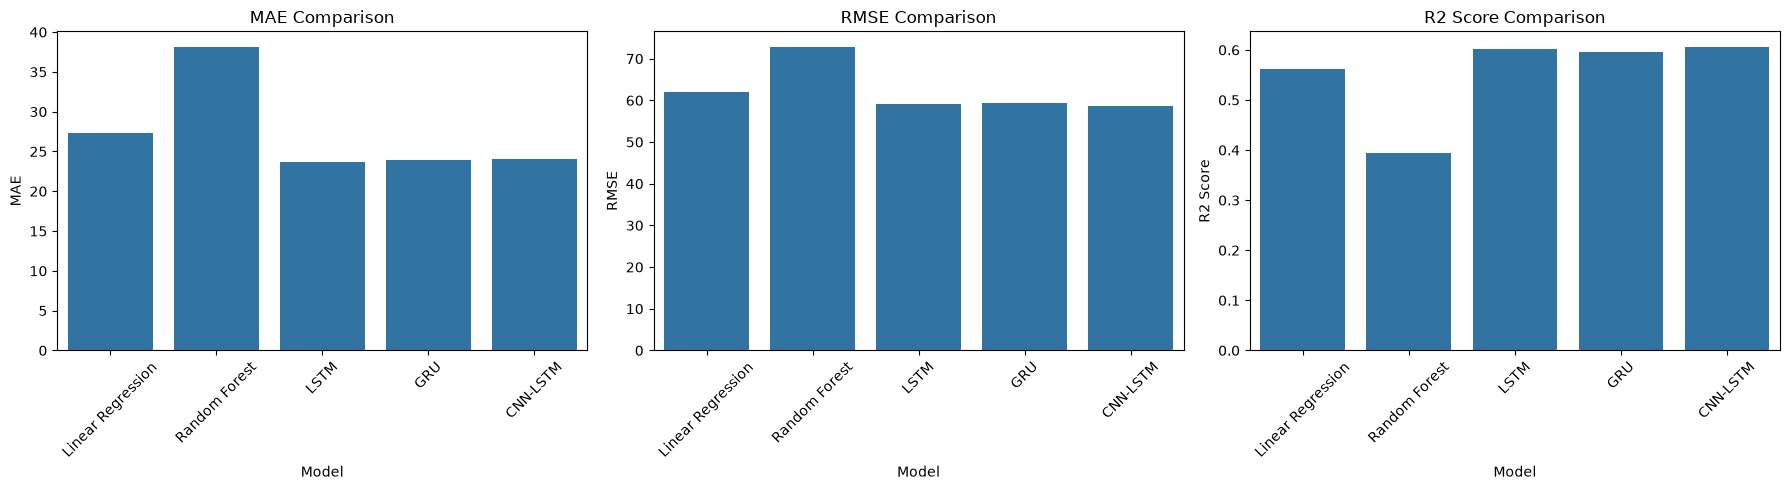

In [452]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE comparison
sns.barplot(
    data=model_comparison,
    x="Model",
    y="MAE",
    ax=axes[0]
)
axes[0].set_title("MAE Comparison")
axes[0].tick_params(axis="x", rotation=45)

# RMSE comparison
sns.barplot(
    data=model_comparison,
    x="Model",
    y="RMSE",
    ax=axes[1]
)
axes[1].set_title("RMSE Comparison")
axes[1].tick_params(axis="x", rotation=45)

# R2 comparison
sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2 Score",
    ax=axes[2]
)
axes[2].set_title("R2 Score Comparison")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [453]:

from pathlib import Path

# Create models directory
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

print("Models directory:", models_dir.resolve())


Models directory: /Users/mohamedafrar/Documents/Multivariate-Time-Series-Prediction-Using-Deep-Learning/models


In [454]:

# Save LSTM model
torch.save({
    "model_state_dict": lstm_model.state_dict(),
    "input_size": input_size,
    "hidden_size": hidden_size,
    "dropout_rate": dropout_rate,
    "sequence_length": sequence_length
}, models_dir / "lstm_model.pth")


# Save GRU model
torch.save({
    "model_state_dict": gru_model.state_dict(),
    "input_size": input_size,
    "hidden_size": hidden_size,
    "dropout_rate": dropout_rate,
    "sequence_length": sequence_length
}, models_dir / "gru_model.pth")


# Save CNN-LSTM model
torch.save({
    "model_state_dict": cnn_lstm_model.state_dict(),
    "input_size": input_size,
    "hidden_size": hidden_size,
    "dropout_rate": dropout_rate,
    "sequence_length": sequence_length
}, models_dir / "cnn_lstm_model.pth")


print("All deep learning models saved successfully")


All deep learning models saved successfully


In [455]:

print("Saved model files:")

for file in sorted(models_dir.iterdir()):
    print(file.name)


Saved model files:
.DS_Store
X_scaler.pkl
cnn_lstm_model.pth
cnn_lstm_optimized_model.pth
feature_columns.pkl
gru_model.pth
gru_optimized_model.pth
linear_regression.pkl
lstm_model.pth
lstm_optimized_model.pth
random_forest.pkl
y_scaler.pkl
